# IRIS — Financial Sentiment
**Financial DistilRoBERTa + Parser V3** · TF-IDF baseline · Node.js + ONNX FP32

Muat model, jalankan contoh inferensi, lalu lihat hasil training baseline dan screening manusia.

## Model dan target

Model mengklasifikasikan **sentimen finansial keseluruhan teks** menjadi `negative`,
`neutral`, atau `positive`. Efek terhadap BTC dinilai sebagai sumbu terpisah.

| Komponen | Metode |
|---|---|
| Financial DistilRoBERTa | Checkpoint hasil fine-tuning upstream; belum di-fine-tune ulang oleh IRIS |
| TF-IDF + Logistic Regression | Baseline dilatih dengan label heuristik |
| Parser V3 | Aturan scope negasi, stance, dan arah usulan |
| ONNX FP32 | Ekspor bobot untuk inferensi di Node.js |

## Setup

Gunakan **Python 3.13 dan Node.js 22+**, instal `requirements.txt`, lalu **Run All**.
Loader memakai bobot lokal IRIS jika tersedia atau mengunduh ONNX sekali (329 MB).

In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Mendukung kernel yang dimulai dari folder notebook maupun root repository.
notebook_dir = next((p for p in [Path.cwd(), Path.cwd() / 'services/sentiment-node/notebooks']
                     if (p / 'data/evidence_snapshot.json').is_file()), None)
if notebook_dir is None:
    raise FileNotFoundError('Buka folder notebook lengkap bersama direktori data/.')
snapshot_path = notebook_dir / 'data/evidence_snapshot.json'
evidence = json.loads(snapshot_path.read_text(encoding='utf-8'))
assert evidence['schema'] == 'iris-sentiment-notebook-evidence/v1'

pd.set_option('display.max_rows', 14)
pd.set_option('display.max_columns', 8)
pd.set_option('display.max_colwidth', 72)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white',
                     'axes.facecolor': 'white', 'savefig.bbox': 'tight'})
COLORS = {'TF-IDF': '#A67828', 'DistilRoBERTa': '#315D8A'}
LABELS = ['negative', 'neutral', 'positive']

## 1. Muat model

**Checkpoint:** [mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis](https://huggingface.co/mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis)  
**Bobot ONNX:** [model.onnx di Git LFS IRIS-Terminal](https://github.com/mirzamhy/IRIS-Terminal/blob/0347974ba293d79c9c679e81bf5be8b6099ff47d/services/sentiment-node/models/onnx-fp32/model.onnx)

Checkpoint ini sudah di-fine-tune pada **Financial PhraseBank**. Sel berikut memuat ekspor
ONNX FP32-nya beserta tokenizer, parser V3, dan baseline TF-IDF.

In [2]:
import hashlib
import os
import shutil
import subprocess
import urllib.request

MODEL_ID = 'mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis'
MODEL_REVISION = 'ae0eab9ad336d7d548e0efe394b07c04bcaf6e91'
WEIGHTS_COMMIT = '0347974ba293d79c9c679e81bf5be8b6099ff47d'
MODEL_URL = (f'https://media.githubusercontent.com/media/mirzamhy/IRIS-Terminal/{WEIGHTS_COMMIT}/'
             'services/sentiment-node/models/onnx-fp32/model.onnx')
runtime_dir = notebook_dir / 'runtime'
model_dir = runtime_dir / 'models/onnx-fp32'
model_path = model_dir / 'model.onnx'
runtime_manifest = json.loads((model_dir / 'manifest.json').read_text(encoding='utf-8'))
assert runtime_manifest['model_id'] == f'{MODEL_ID}@{MODEL_REVISION}'

def file_digest(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def valid_weight(path):
    expected = runtime_manifest['files']['model.onnx']
    return (path.is_file() and path.stat().st_size == expected['bytes']
            and file_digest(path) == expected['sha256'])

if valid_weight(model_path):
    weight_origin = 'Cache lokal notebook'
else:
    local_weight = notebook_dir.parent / 'models/onnx-fp32/model.onnx'
    if valid_weight(local_weight):
        shutil.copyfile(local_weight, model_path)
        weight_origin = 'Bobot lokal IRIS-Terminal'
    else:
        print('Mengunduh ONNX FP32 (329 MB)...')
        temporary_path = model_path.with_suffix('.onnx.part')
        request = urllib.request.Request(MODEL_URL, headers={'User-Agent': 'IRIS-notebook'})
        with urllib.request.urlopen(request, timeout=60) as response, temporary_path.open('wb') as stream:
            shutil.copyfileobj(response, stream, length=1024 * 1024)
        if not valid_weight(temporary_path):
            raise ValueError('Bobot tidak cocok dengan manifest ONNX.')
        temporary_path.replace(model_path)
        weight_origin = 'Git LFS IRIS-Terminal'
assert valid_weight(model_path)
print(f'Model siap: {model_path.name} ({model_path.stat().st_size / 1_000_000:.1f} MB) — {weight_origin}')

Model siap: model.onnx (328.6 MB) — Bobot lokal IRIS-Terminal


### Runtime Node.js

Modul inferensi yang dipakai sama dengan aplikasi. Dependensi npm dipasang sekali ke `runtime/`.

In [3]:
node_bin = shutil.which('node')
npm_bin = shutil.which('npm.cmd' if os.name == 'nt' else 'npm')
if node_bin is None or npm_bin is None:
    raise RuntimeError('Pasang Node.js 22+ beserta npm, lalu restart kernel.')
node_version = subprocess.check_output([node_bin, '--version'], text=True).strip()
if int(node_version.removeprefix('v').split('.')[0]) < 22:
    raise RuntimeError(f'Node.js 22+ diperlukan; ditemukan {node_version}.')
runtime_package = json.loads((runtime_dir / 'package.json').read_text(encoding='utf-8'))
dependencies_ready = True
for name, version in runtime_package['dependencies'].items():
    dependency = runtime_dir / 'node_modules' / name / 'package.json'
    if not dependency.is_file() or json.loads(dependency.read_text(encoding='utf-8'))['version'] != version:
        dependencies_ready = False
        break
if not dependencies_ready:
    installation = subprocess.run([npm_bin, 'ci', '--no-audit', '--no-fund'], cwd=runtime_dir,
                                  capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=180)
    if installation.returncode:
        raise RuntimeError(installation.stderr[-3000:] or installation.stdout[-3000:])
print(f'{node_version} · ONNX Runtime {runtime_package["dependencies"]["onnxruntime-node"]} · tokenizer siap')

v22.23.3 · ONNX Runtime 1.30.0 · tokenizer siap


### Coba inferensi

Ubah `sample_texts` untuk mencoba berita lain. Kolom probabilitas berasal dari neural model;
kolom V3 menunjukkan label setelah parser.

In [4]:
sample_texts = [
    "The company's net profit increased by 25% this quarter.",
    'The company reported a significant loss and declining revenue.',
    'The bank supports Bitcoin adoption.',
]
node_script = r"""
import { readFileSync } from 'node:fs';
import { pathToFileURL } from 'node:url';
const request = JSON.parse(readFileSync(0, 'utf8'));
const { loadModel } = await import(pathToFileURL(request.module).href);
const model = await loadModel({ threads: 4 });
try {
  const results = await model.infer(request.texts);
  const encodings = request.texts.map(text => model.encode(text));
  console.log(JSON.stringify({ model_id: model.manifest.model_id,
    tokenizer_loaded: true, encodings, results }));
} finally {
  await model.close();
}
"""
request = {'module': str((runtime_dir / 'node/model.mjs').resolve()), 'texts': sample_texts}
inference_run = subprocess.run([node_bin, '--input-type=module', '-e', node_script],
    input=json.dumps(request), capture_output=True, text=True, encoding='utf-8',
    errors='replace', cwd=runtime_dir, timeout=120)
if inference_run.returncode:
    raise RuntimeError(inference_run.stderr[-3000:] or inference_run.stdout[-3000:])
live_inference = json.loads(inference_run.stdout)
assert live_inference['model_id'] == f'{MODEL_ID}@{MODEL_REVISION}'
assert live_inference['tokenizer_loaded'] is True
assert len(live_inference['results']) == len(sample_texts)
inference_rows = []
for text, item in zip(sample_texts, live_inference['results']):
    prediction = item['prediction']
    probabilities = prediction['probabilities']
    assert math.isclose(sum(probabilities.values()), 1.0, abs_tol=1e-6)
    inference_rows.append({'Teks': text, 'Neural': prediction['model_sentiment'],
        **{f'P({label})': probabilities[label] for label in LABELS},
        'V3': prediction['sentiment'], 'TF-IDF': item['baseline']['sentiment']})
live_predictions = pd.DataFrame(inference_rows)
display(live_predictions.style.format({f'P({label})': '{:.4f}' for label in LABELS})
        .set_properties(**{'white-space': 'normal', 'text-align': 'left'}).hide(axis='index'))

Teks,Neural,P(negative),P(neutral),P(positive),V3,TF-IDF
The company's net profit increased by 25% this quarter.,positive,0.0002,0.0001,0.9997,positive,neutral
The company reported a significant loss and declining revenue.,negative,0.9988,0.0005,0.0007,negative,negative
The bank supports Bitcoin adoption.,neutral,0.0001,0.9998,0.0001,positive,positive


### Training upstream

Parameter dan log training berikut berasal dari model card pembuat checkpoint.

In [5]:
upstream = evidence['upstream']
display(pd.DataFrame(upstream['hyperparameters_reported'].items(),
                     columns=['Parameter upstream', 'Nilai yang dilaporkan']).set_index('Parameter upstream'))
upstream_log = pd.DataFrame(upstream['epochs_reported'])
display(upstream_log.rename(columns={'epoch': 'Epoch', 'step': 'Step',
    'training_loss_reported': 'Training loss tercatat', 'validation_loss': 'Validation loss',
    'accuracy': 'Validation accuracy'}).style.format(precision=4, na_rep='Tidak dicatat').hide(axis='index'))

,Nilai yang dilaporkan
Parameter upstream,
learning_rate,2e-05
train_batch_size,8
eval_batch_size,8
seed,42
optimizer,"Adam with betas=(0.9,0.999) and epsilon=1e-08"
lr_scheduler_type,linear
num_epochs,5


Epoch,Step,Training loss tercatat,Validation loss,Validation accuracy
1,255,Tidak dicatat,0.1670,0.9646
2,510,0.2090,0.2290,0.9558
3,765,0.2090,0.2044,0.9558
4,1020,0.0326,0.1116,0.9823
5,1275,0.0326,0.1127,0.9779


### Alur inferensi

**Teks → token BPE → embedding → 6 layer Transformer → classification head → softmax → sentimen.**

Self-attention membentuk representasi konteks. Classifier mengambil token awal `<s>`,
lalu menerapkan `dense 768 → 768`, `tanh`, dan proyeksi `768 → 3`.
Wrapper Node.js mengubah logits menjadi probabilitas dengan softmax.

In [6]:
config = evidence['model_config']
architecture = {
    'Arsitektur': config['architectures'][0],
    'Layer Transformer': config['num_hidden_layers'],
    'Hidden size per token': config['hidden_size'],
    'Attention head per layer': config['num_attention_heads'],
    'Dimensi per head': config['hidden_size'] // config['num_attention_heads'],
    'Feed-forward intermediate': config['intermediate_size'],
    'Vocabulary': config['vocab_size'],
    'Batas input termasuk token khusus': evidence['onnx_manifest']['max_tokens'],
}
display(pd.DataFrame(architecture.items(), columns=['Bagian', 'Konfigurasi']).set_index('Bagian'))

# Ilustrasi softmax saja: logits ini bukan keluaran model atas suatu berita.
illustrative_logits = np.array([-1.0, 0.0, 2.0])
exp = np.exp(illustrative_logits - illustrative_logits.max())
illustrative_probabilities = exp / exp.sum()
assert math.isclose(float(illustrative_probabilities.sum()), 1.0)
display(pd.DataFrame({'Kelas': LABELS, 'Logit ilustratif': illustrative_logits,
                      'Probabilitas ilustratif': illustrative_probabilities})
        .set_index('Kelas').style.format(precision=4))

,Konfigurasi
Bagian,
Arsitektur,RobertaForSequenceClassification
Layer Transformer,6
Hidden size per token,768
Attention head per layer,12
Dimensi per head,64
Feed-forward intermediate,3072
Vocabulary,50265
Batas input termasuk token khusus,512


,Logit ilustratif,Probabilitas ilustratif
Kelas,,
negative,-1.0000,0.0420
neutral,0.0000,0.1142
positive,2.0000,0.8438


Bentuk tensor: input `[batch, token]`, keluaran encoder `[batch, token, 768]`,
dan logits `[batch, 3]`. Contoh softmax di atas memakai angka ilustratif.

## 2. Training baseline

Weak label diambil dari `assessment.result.sentiment.polarity`: negatif → `negative`,
nol → `neutral`, positif → `positive`. Data dibersihkan dan dideduplikasi.

TF-IDF memakai unigram/bigram; Logistic Regression memakai bobot kelas `balanced`.
Kandidat `C = 0.5, 2.0, 8.0` dipilih lewat macro-F1 validation.
Split mengikuti urutan tanggal publikasi: sekitar 70% tanggal untuk train,
15% validation, dan 15% test. Jumlah record per split mengikuti distribusi tanggal tersebut.

In [7]:
baseline = evidence['baseline']
audit = baseline['audit']
assert audit['input'] - audit['invalid_timestamp'] - audit['empty'] - audit['missing_label'] - audit['duplicates'] == audit['retained']
assert sum(part['count'] for part in baseline['split'].values()) == audit['retained']
display(pd.DataFrame(evidence['baseline_configuration'].items(),
                     columns=['Konfigurasi baseline', 'Nilai']).set_index('Konfigurasi baseline'))
split_rows = []
for split, part in baseline['split'].items():
    assert sum(part['labels'].values()) == part['count']
    split_rows.append({'Split': split, 'Mulai (UTC)': part['start'][:10],
                      'Selesai (UTC)': part['end'][:10], 'Jumlah': part['count'],
                      **{label: part['labels'][label] for label in LABELS}})
display(pd.DataFrame(split_rows).set_index('Split'))
display(Markdown(f"**Audit input:** {audit['input']:,} → {audit['retained']:,} record; "
    f"{audit['invalid_timestamp']:,} timestamp tidak valid dan {audit['duplicates']:,} duplikasi disaring."))

,Nilai
Konfigurasi baseline,
vectorizer,TfidfVectorizer
ngram_range,"[1, 2]"
min_df,2
max_features,40000
sublinear_tf,True
normalization,l2 (default)
classifier,LogisticRegression
class_weight,balanced
max_iter,1000


,Mulai (UTC),Selesai (UTC),Jumlah,negative,neutral,positive
Split,,,,,,
train,2022-08-23,2025-07-12,5279,381,4742,156
validation,2025-07-13,2026-02-03,1600,90,1472,38
test,2026-02-04,2026-08-23,1558,140,1317,101


**Audit input:** 9,471 → 8,437 record; 705 timestamp tidak valid dan 329 duplikasi disaring.

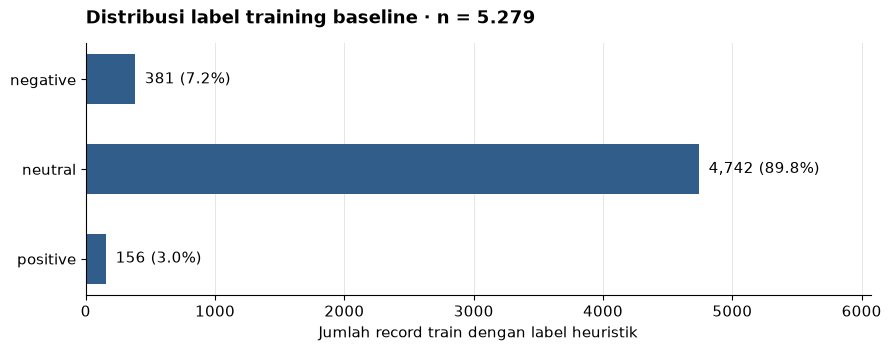

In [8]:
training_counts = baseline['split']['train']['labels']
fig, ax = plt.subplots(figsize=(8.8, 3.4), layout='constrained')
counts = [training_counts[label] for label in LABELS]
bars = ax.barh(LABELS, counts, color='#315D8A', height=0.56)
ax.bar_label(bars, labels=[f'{value:,} ({value/sum(counts):.1%})' for value in counts], padding=7)
ax.set_xlim(0, max(counts) * 1.28)
ax.invert_yaxis()
ax.set_xlabel('Jumlah record train dengan label heuristik')
ax.set_title('Distribusi label training baseline · n = 5.279', loc='left', pad=14)
ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
ax.set_axisbelow(True)
plt.show()

In [9]:
candidates = pd.DataFrame(baseline['candidates'])
assert float(candidates.loc[candidates['validation_macro_f1'].idxmax(), 'C']) == baseline['selected_C']
display(candidates.rename(columns={'validation_macro_f1': 'Macro-F1 validation (heuristik)'})
        .style.format({'C': '{:.1f}', 'Macro-F1 validation (heuristik)': '{:.4f}'}))
display(pd.DataFrame([{'Populasi': '1.558 test record, label heuristik',
    'Macro-F1': baseline['test']['macro avg']['f1-score'],
    'Accuracy': baseline['test']['accuracy']}]).style.format({'Macro-F1': '{:.4f}', 'Accuracy': '{:.2%}'}))

,C,Macro-F1 validation (heuristik)
0,0.5,0.9016
1,2.0,0.9028
2,8.0,0.9323


,Populasi,Macro-F1,Accuracy
0,"1.558 test record, label heuristik",0.8740,95.64%


Skor test **0,8740 macro-F1** menggunakan 1.558 record berlabel heuristik.
Evaluasi terhadap label manusia disajikan terpisah di bawah.

## 3. Screening manusia

Sebanyak **120 berita** dianotasi oleh Vian: **114 label pasti** masuk metrik tiga kelas
dan **6 uncertain** dilaporkan terpisah. **10 stress case** berada di luar metrik utama.

Gold v2 memuat adjudikasi lima berita minyak menjadi `positive`, dengan efek BTC tetap
`unknown`. Prediksi tidak berubah; perubahan skor v1 → v2 berasal dari revisi label acuan.
Sampel dipilih menurut weak labels dan belum mewakili prevalensi seluruh sumber berita.

In [10]:
human = evidence['human_v2']
assert human['real_news_count'] == human['evaluated_count'] + human['uncertain']['count']
assert human['stress']['included_in_main_metrics'] is False
assert evidence['human_v1']['predictions_sha256'] == human['predictions_sha256']
assert human['adjudication']['approved_count'] == 5
assert human['adjudication']['model_predictions_changed'] is False
display(pd.DataFrame([
    {'Bagian': 'Seluruh berita asli', 'Jumlah': human['real_news_count'], 'Peran': 'Screening manusia'},
    {'Bagian': 'Label pasti', 'Jumlah': human['evaluated_count'], 'Peran': 'Metrik tiga kelas'},
    {'Bagian': 'Uncertain', 'Jumlah': human['uncertain']['count'], 'Peran': 'Laporan terpisah'},
    {'Bagian': 'Stress case', 'Jumlah': human['stress']['count'], 'Peran': 'Diagnostik terpisah'},
]).set_index('Bagian'))

,Jumlah,Peran
Bagian,,
Seluruh berita asli,120,Screening manusia
Label pasti,114,Metrik tiga kelas
Uncertain,6,Laporan terpisah
Stress case,10,Diagnostik terpisah


### Metrik

Macro-F1 dan accuracy dihitung ulang dari confusion matrix: baris adalah label manusia,
kolom adalah prediksi. Kedua model dinilai pada 114 berita yang sama.

In [11]:
def metrics_from_confusion(matrix):
    matrix = np.asarray(matrix, dtype=int)
    true_positive = np.diag(matrix)
    true_count = matrix.sum(axis=1)
    predicted_count = matrix.sum(axis=0)
    denominator = true_count + predicted_count
    f1 = np.divide(2.0 * true_positive, denominator,
                   out=np.zeros(3, dtype=float), where=denominator != 0)
    return float(f1.mean()), float(true_positive.sum() / matrix.sum())

comparison_rows = []
for version in ['human_v1', 'human_v2']:
    for backend, name in [('tfidf', 'TF-IDF'), ('financial_distilroberta', 'DistilRoBERTa')]:
        result = evidence[version]['models'][backend]
        matrix = result['confusion_matrix_true_rows_predicted_columns']
        f1, accuracy = metrics_from_confusion(matrix)
        assert np.asarray(matrix).sum() == evidence[version]['evaluated_count']
        assert math.isclose(f1, result['macro_f1'], abs_tol=1e-12)
        assert math.isclose(accuracy, result['accuracy'], abs_tol=1e-12)
        comparison_rows.append({'Gold': version.replace('human_', ''), 'Model': name,
                                'n': result['evaluated_count'], 'Macro-F1': f1, 'Accuracy': accuracy})
human_comparison = pd.DataFrame(comparison_rows)
display(human_comparison.style.format({'Macro-F1': '{:.4f}', 'Accuracy': '{:.2%}'}).hide(axis='index'))

Gold,Model,n,Macro-F1,Accuracy
v1,TF-IDF,114,0.3631,37.72%
v1,DistilRoBERTa,114,0.5947,62.28%
v2,TF-IDF,114,0.3928,40.35%
v2,DistilRoBERTa,114,0.6318,66.67%


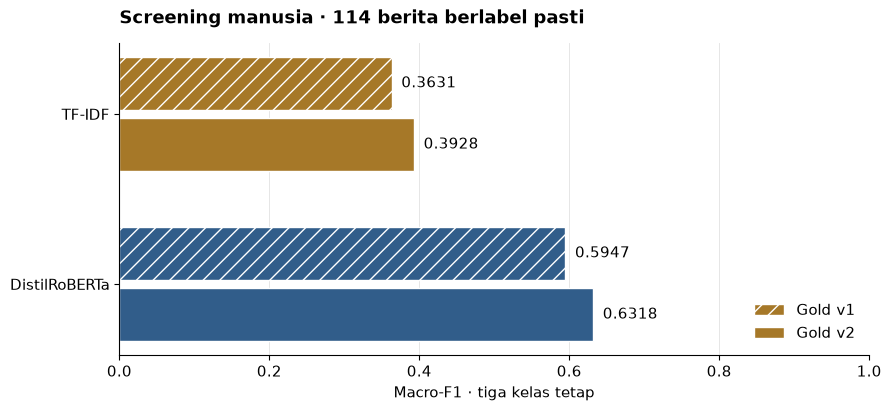

In [12]:
fig, ax = plt.subplots(figsize=(8.8, 4.0), layout='constrained')
models = ['TF-IDF', 'DistilRoBERTa']
positions = np.arange(len(models))
for offset, version, hatch in [(-0.18, 'v1', '//'), (0.18, 'v2', '')]:
    values = [float(human_comparison.query('Gold == @version and Model == @name')['Macro-F1'].iloc[0])
              for name in models]
    bars = ax.barh(positions + offset, values, height=0.31,
                   color=[COLORS[name] for name in models], hatch=hatch, edgecolor='white', label=f'Gold {version}')
    ax.bar_label(bars, labels=[f'{value:.4f}' for value in values], padding=7)
ax.set_yticks(positions, models)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('Macro-F1 · tiga kelas tetap')
ax.set_title('Screening manusia · 114 berita berlabel pasti', loc='left', pad=14)
ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=False)
plt.show()

In [13]:
class_rows = []
for backend, name in [('tfidf', 'TF-IDF'), ('financial_distilroberta', 'DistilRoBERTa')]:
    for label in LABELS:
        row = human['models'][backend]['classification_report'][label]
        class_rows.append({'Model': name, 'Kelas': label, 'Support': int(row['support']),
                           'Precision': row['precision'], 'Recall': row['recall'], 'F1': row['f1-score']})
display(pd.DataFrame(class_rows).style.format({'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}'}).hide(axis='index'))
paired = human['paired_outcomes']
assert sum(paired.values()) == human['evaluated_count']
display(pd.DataFrame(paired.items(), columns=['Hasil berpasangan', 'Jumlah']).set_index('Hasil berpasangan'))

Model,Kelas,Support,Precision,Recall,F1
TF-IDF,negative,56,0.7419,0.4107,0.5287
TF-IDF,neutral,12,0.1579,0.7500,0.2609
TF-IDF,positive,46,0.5385,0.3043,0.3889
DistilRoBERTa,negative,56,0.8718,0.6071,0.7158
DistilRoBERTa,neutral,12,0.3333,0.8333,0.4762
DistilRoBERTa,positive,46,0.7111,0.6957,0.7033


,Jumlah
Hasil berpasangan,
both_correct,42
tfidf_only_correct,4
financial_only_correct,34
both_wrong,34


### Uncertain dan efek BTC

Tabel pertama menunjukkan prediksi model pada enam berita beracuan `uncertain`.
Model tidak menghasilkan label efek BTC, sehingga metrik prediksi efek BTC belum dihitung.

In [14]:
uncertain_rows = []
for backend, name in [('tfidf', 'TF-IDF'), ('financial_distilroberta', 'DistilRoBERTa')]:
    counts = human['models'][backend]['uncertain_predictions']
    assert sum(counts.values()) == human['uncertain']['count']
    uncertain_rows.append({'Model': name, **{label: counts.get(label, 0) for label in LABELS}})
display(pd.DataFrame(uncertain_rows).set_index('Model'))
btc = human['btc_effect']
assert btc['model_predictions_available'] is False
assert sum(btc['label_counts'].values()) == btc['annotation_count']
display(pd.DataFrame(btc['label_counts'].items(), columns=['Anotasi efek BTC', 'Jumlah']).set_index('Anotasi efek BTC'))

,negative,neutral,positive
Model,,,
TF-IDF,1,5,0
DistilRoBERTa,1,3,2


,Jumlah
Anotasi efek BTC,
not_applicable,24
negative,21
positive,10
unknown,62
neutral,3


## 4. Diagnostik parser V3

Parser memeriksa pemegang stance, target, negasi, dan arah usulan. Jika aturan eligible,
label akhir mengikuti kandidat parser; jika abstain, label model dipertahankan.
Probabilitas neural tetap sama.

Setelah aturan dibekukan, pengujian memakai **40 teks sintetis**: 30 struktur baru dan
10 kontrol. Metrik label memakai **24 acuan pasti**; **16 uncertain** dipisahkan.
Acuan berasal dari analis, sehingga hasil diagnostik ini terpisah dari gold manusia.

In [15]:
diagnostic = evidence['diagnostic_v3']
assert diagnostic['included_in_main_metrics'] is False
assert diagnostic['fresh_examples'] == sum(diagnostic['reference_counts'].values())
diagnostic_rows = []
for backend, name in [('tfidf', 'TF-IDF'), ('financial_distilroberta', 'DistilRoBERTa')]:
    for arm in ['model_only', 'model_plus_v1', 'model_plus_v2', 'model_plus_v3']:
        result = diagnostic['models'][backend]['arms'][arm]
        report = result['classification_report']
        f1_from_report = np.mean([report[label]['f1-score'] for label in LABELS])
        assert math.isclose(float(f1_from_report), result['macro_f1'], abs_tol=1e-12)
        assert result['total'] == 24 and result['uncertain_excluded'] == 16
        diagnostic_rows.append({'Model': name, 'Arm': arm, 'Benar /24': result['correct'],
                                'Macro-F1 diagnostik': result['macro_f1']})
diagnostic_table = pd.DataFrame(diagnostic_rows)
display(diagnostic_table.style.format({'Macro-F1 diagnostik': '{:.4f}'}).hide(axis='index'))

Model,Arm,Benar /24,Macro-F1 diagnostik
TF-IDF,model_only,10,0.3313
TF-IDF,model_plus_v1,21,0.9124
TF-IDF,model_plus_v2,19,0.8506
TF-IDF,model_plus_v3,22,0.9419
DistilRoBERTa,model_only,2,0.0766
DistilRoBERTa,model_plus_v1,16,0.5930
DistilRoBERTa,model_plus_v2,13,0.5088
DistilRoBERTa,model_plus_v3,16,0.5889


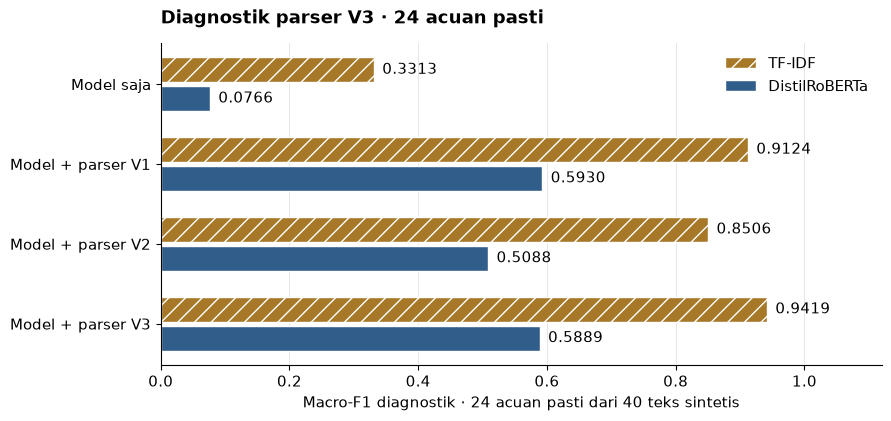

In [16]:
fig, ax = plt.subplots(figsize=(8.8, 4.1), layout='constrained')
arm_labels = {'model_only': 'Model saja', 'model_plus_v1': 'Model + parser V1',
              'model_plus_v2': 'Model + parser V2', 'model_plus_v3': 'Model + parser V3'}
positions = np.arange(4)
for name, offset, hatch in [('TF-IDF', -0.18, '//'), ('DistilRoBERTa', 0.18, '')]:
    subset = diagnostic_table[diagnostic_table['Model'] == name]
    bars = ax.barh(positions + offset, subset['Macro-F1 diagnostik'], height=0.31,
                   color=COLORS[name], hatch=hatch, edgecolor='white', label=name)
    ax.bar_label(bars, labels=[f'{value:.4f}' for value in subset['Macro-F1 diagnostik']], padding=6)
ax.set_yticks(positions, list(arm_labels.values()))
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xticks(np.linspace(0, 1, 6))
ax.set_xlabel('Macro-F1 diagnostik · 24 acuan pasti dari 40 teks sintetis')
ax.set_title('Diagnostik parser V3 · 24 acuan pasti', loc='left', pad=14)
ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
ax.set_axisbelow(True)
ax.legend(loc='upper right', frameon=False)
plt.show()

In [17]:
action_rows = []
for version, result in diagnostic['action_metrics'].items():
    action_rows.append({'Policy': version, 'Action sesuai /40': result['correct'],
                       'Eligible /40': result['eligible'], 'Unsafe /18': result['unsafe_applications'],
                       'Missed /22': result['missed_eligible']})
display(pd.DataFrame(action_rows).set_index('Policy'))
assert diagnostic['action_metrics']['v3']['unsafe_applications'] == 0

,Action sesuai /40,Eligible /40,Unsafe /18,Missed /22
Policy,,,,
v1,23,27,11,6
v2,26,18,5,9
v3,34,16,0,6


V3 menerapkan aturan pada **16/40** contoh, dengan **0/18 unsafe** dan **6/22 missed eligible**.
Fokus perbaikannya adalah selektivitas: macro-F1 neural V3 **0,5889**, sedangkan V1 **0,5930**.

## 5. ONNX dan Node.js

Bobot diekspor ke **ONNX FP32, opset 17**, lalu dijalankan dengan ONNX Runtime CPU.
Cache menyimpan hasil selesai, `inFlight` membagikan pekerjaan identik,
dan antrean membatasi batch aktif.

Hasil pengujian clone baru pada **18 Oktober 2026**:

In [18]:
manifest = evidence['onnx_manifest']
validation = evidence['clone_validation_20261018']
assert manifest['precision'] == 'fp32' and manifest['quantized'] is False and manifest['trained'] is False
assert validation['trained'] is False and validation['gold_holdout_used'] is False
runtime_rows = [
    ('Format / opset', f"{manifest['precision'].upper()} / {manifest['opset']}"),
    ('Unit test lulus', validation['unit_tests_passed']),
    ('Contoh parity sintetis', validation['synthetic_parity_examples']),
    ('Selisih maksimum probabilitas neural', f"{validation['neural_max_probability_delta']:.3e}"),
    ('Request HTTP bersamaan', validation['concurrent_http_requests']),
    ('Inferensi teks unik setelah deduplikasi', validation['unique_inferences']),
    ('Batas batch aktif teramati', validation['active_batch_limit_observed']),
    ('Warm cache terverifikasi', validation['warm_cache_verified']),
    ('Unduh model via Git LFS pada clone baru', validation['model_fetched_using_git_lfs_pull']),
]
display(pd.DataFrame(runtime_rows, columns=['Pemeriksaan', 'Hasil']).set_index('Pemeriksaan'))

,Hasil
Pemeriksaan,
Format / opset,FP32 / 17
Unit test lulus,16
Contoh parity sintetis,66
Selisih maksimum probabilitas neural,3.615e-06
Request HTTP bersamaan,32
Inferensi teks unik setelah deduplikasi,16
Batas batch aktif teramati,1
Warm cache terverifikasi,True
Unduh model via Git LFS pada clone baru,True


## Hasil

- Pada gold v2, DistilRoBERTa mencapai **0,6318 macro-F1** dan **66,67% accuracy**;
  TF-IDF mencapai **0,3928** dan **40,35%**.
- Parser V3 dan backend ONNX sudah diuji secara diagnostik dan teknis.
- Langkah berikutnya adalah screening manusia independen untuk pipeline final V3.
  Reserved holdout tetap belum digunakan.

## Sumber

Rincian konfigurasi dan hasil tersedia dalam snapshot pendamping.
Lihat [README model](../models/onnx-fp32/README.md),
[README layanan](../README.md), dan [model card](../UPSTREAM-MODEL-CARD.md).

In [19]:
source_rows = [{'Repository': item['repository'], 'Sumber': item['path'], 'Kegunaan': item['purpose']}
               for item in evidence['sources']]
display(pd.DataFrame(source_rows).style.set_properties(**{'text-align': 'left',
        'white-space': 'normal', 'overflow-wrap': 'anywhere'}).hide(axis='index'))

Repository,Sumber,Kegunaan
bitcoin-iris,artifacts/news/sentiment-v1-20261016/baseline/evaluation.json,"Audit data, temporal split, pemilihan C dan evaluasi weak-label baseline"
bitcoin-iris,news_pipeline/__main__.py,Konfigurasi training baseline
bitcoin-iris,news_pipeline/core.py,Pembentukan weak label dan temporal split
bitcoin-iris,artifacts/news/sentiment-v1-20261016/human-evaluation-20261017/summary.json,"Evaluasi manusia gold v1; hanya agregat, tanpa teks atau anotasi per berita"
bitcoin-iris,artifacts/news/sentiment-v1-20261016/human-evaluation-20261017-v2/summary.json,"Evaluasi manusia gold v2; hanya agregat, tanpa teks atau anotasi per berita"
bitcoin-iris,artifacts/news/sentiment-scope-v3-fresh-challenge-20261017/summary.json,Diagnostik sintetis setelah freeze V3; terpisah dari gold manusia
IRIS-Terminal,services/sentiment-node/models/onnx-fp32/config.json,Dimensi arsitektur model
IRIS-Terminal,services/sentiment-node/models/onnx-fp32/manifest.json,Identitas ekspor ONNX FP32
IRIS-Terminal,services/sentiment-node/UPSTREAM-MODEL-CARD.md,Training upstream yang dilaporkan pembuat checkpoint
IRIS-Terminal,.local/sentiment-lfs-20261018/clone-validation.json,Catatan pengujian clone baru pada 18 Oktober 2026
